# Deep Dive: CUDA Concept and Programming — Terrain Generation

**Project:** CPU vs. GPU Terrain Generation: Measuring When CUDA Beats Sequential C++.

This is the graded **Deep Dive assignment** that builds on the group's revised proposal; it is **not automatically the same as proposal Milestone #2**.

This notebook builds a deterministic terrain heightmap, compares CPU scalar, x86-64 scalar, XMM, YMM, and four CUDA grid-stride Unified Memory variants, checks results against the sequential reference, measures **30 timed kernel executions per CUDA variant**, and attempts `nsys`/`ncu` profiling. All reported GPU numbers must be produced by running on a real NVIDIA GPU; nothing is pre-filled.

**Setup:** In Colab, use **Runtime → Change runtime type → GPU** before running. Run top to bottom. For full results, keep the same CPU/GPU environment for all comparisons.

In [1]:
from pathlib import Path
import subprocess, shutil, os, platform
for d in ('src','results','screenshots','profiles'):
    Path(d).mkdir(parents=True,exist_ok=True)
print('System:',platform.platform())
print('nvcc:',shutil.which('nvcc'))
print('nsys:',shutil.which('nsys'))
print('ncu:',shutil.which('ncu'))
if shutil.which('nvidia-smi'):
    subprocess.run(['nvidia-smi'],check=False)
else:
    print('No nvidia-smi detected: CUDA executions cannot run until a GPU runtime is enabled.')

System: Linux-6.6.159+-x86_64-with-glibc2.39
nvcc: /usr/local/cuda/bin/nvcc
nsys: /usr/local/bin/nsys
ncu: /usr/local/cuda/bin/ncu


## Experimental controls

Default **4096 × 4096 = 2^24 columns**, **hilly** type, **4 octaves**, fixed seed `3762183612631`, and **30 measured repetitions**. Heights are calculated from `x,z` and one seeded 512-byte permutation table (rather than initialized independent input vectors). GPU blocks = 256/512/1024; first use 256 for the required version comparison.

In [2]:
WIDTH = 4096
HEIGHT = 4096
TYPE = 1              # 0 plains, 1 hilly, 2 mountains
OCTAVES = 4          # use 2/4/6 for terrain type defaults respectively
SEED = 3762183612631
BLOCK = 256
REPEATS = 30
assert REPEATS >= 30
print(f'Workload: {WIDTH}×{HEIGHT}={WIDTH*HEIGHT:,} heights; {REPEATS} measured runs; block={BLOCK}')

Workload: 4096×4096=16,777,216 heights; 30 measured runs; block=256


## Shared specification — terrain formulas

Every version uses this common formula: seeded Fisher–Yates permutation, 2D gradient noise (`fade`, `grad`, `lerp`), `octaves` layers, then `floor`/clamp. The common code ensures each variant does the same workload. CPU-only XMM/YMM use vector math with per-lane permutation-table lookup.

In [3]:
%%writefile src/terrain_math.hpp
#pragma once
#include <cmath>
#include <cstdint>
#include <random>
#include <algorithm>

#ifdef __CUDACC__
#define TERRAIN_HD __host__ __device__
#else
#define TERRAIN_HD
#endif

struct TerrainParams {
    int width = 4096;
    int height = 4096;
    int x0 = 0;
    int z0 = 0;
    int type = 1;                // 0 plains, 1 hilly, 2 mountains
    int octaves = 4;
    float base = 72.0f;
    float amplitude = 24.0f;
    float frequency = 0.008f;
    int ridged = 0;
};

inline TerrainParams make_params(int w, int h, int type, int octave_override = 0) {
    TerrainParams p{};
    p.width = w;
    p.height = h;
    p.type = type;
    if (type == 0) { p.base=64.0f; p.amplitude=8.0f; p.frequency=0.004f; p.octaves=2; p.ridged=0; }
    else if (type == 1) { p.base=72.0f; p.amplitude=24.0f; p.frequency=0.008f; p.octaves=4; p.ridged=0; }
    else { p.base=100.0f; p.amplitude=90.0f; p.frequency=0.004f; p.octaves=6; p.ridged=1; }
    if (octave_override > 0) p.octaves = octave_override;
    return p;
}

inline void make_permutation(uint64_t seed, uint8_t perm[512]) {
    std::mt19937_64 rng(seed);
    uint8_t p[256];
    for (int i=0; i<256; ++i) p[i] = static_cast<uint8_t>(i);
    for (int i=255; i>0; --i) {
        int j = static_cast<int>(rng() % static_cast<uint64_t>(i+1));
        std::swap(p[i], p[j]);
    }
    for (int i=0; i<512; ++i) perm[i] = p[i & 255];
}

TERRAIN_HD inline float terrain_fade(float t) {
    return t*t*t*(t*(t*6.0f-15.0f)+10.0f);
}
TERRAIN_HD inline float terrain_lerp(float t, float a, float b) {
    return a + t*(b-a);
}
TERRAIN_HD inline float terrain_grad(int h, float x, float z) {
    switch (h & 7) {
      case 0: return x;
      case 1: return -x;
      case 2: return z;
      case 3: return -z;
      case 4: return x+z;
      case 5: return -x+z;
      case 6: return x-z;
      default: return -x-z;
    }
}
TERRAIN_HD inline float terrain_noise(float x, float z, const uint8_t* perm) {
    const int xi = static_cast<int>(floorf(x));
    const int zi = static_cast<int>(floorf(z));
    const int X = xi & 255;
    const int Z = zi & 255;
    const float xf = x-static_cast<float>(xi);
    const float zf = z-static_cast<float>(zi);
    const float u = terrain_fade(xf);
    const float v = terrain_fade(zf);
    const int aa=perm[perm[X]+Z], ba=perm[perm[X+1]+Z];
    const int ab=perm[perm[X]+Z+1], bb=perm[perm[X+1]+Z+1];
    return terrain_lerp(v,
        terrain_lerp(u,terrain_grad(aa,xf,zf),terrain_grad(ba,xf-1.0f,zf)),
        terrain_lerp(u,terrain_grad(ab,xf,zf-1.0f),terrain_grad(bb,xf-1.0f,zf-1.0f)));
}
TERRAIN_HD inline int terrain_height_at(int index, const TerrainParams& p, const uint8_t* perm) {
    const int ix = index % p.width;
    const int iz = index / p.width;
    const float xw = static_cast<float>(p.x0+ix);
    const float zw = static_cast<float>(p.z0+iz);
    float sum=0.0f, amp=1.0f, freq=p.frequency, amp_total=0.0f;
    for (int o=0; o<p.octaves; ++o) {
        float n = terrain_noise(xw*freq+17.37f*o, zw*freq+31.91f*o, perm);
        if (p.ridged) n = 1.0f-2.0f*fabsf(n);
        sum += amp*n;
        amp_total += amp;
        freq *= 2.0f;
        amp *= 0.5f;
    }
    int height = static_cast<int>(floorf(p.base+p.amplitude*(sum/amp_total)));
    if (height < -64) height = -64;
    if (height > 319) height = 319;
    return height;
}


Writing src/terrain_math.hpp


In [4]:
%%writefile src/terrain_simd.hpp
#pragma once
// Vectorized x/z samples, noise interpolation, gradients, FBM and height conversion.
// The tiny, random permutation-table lookup is scalar per lane (XMM has no gather).
// SIMD_LANES must be 4 (XMM/SSE4.1) or 8 (YMM/AVX2).
#include "terrain_math.hpp"
#include <immintrin.h>
#include <cstddef>
#include <cstdint>

#if SIMD_LANES == 4
using VF=__m128;
using VI=__m128i;
#define VSET _mm_set1_ps
#define ISET _mm_set1_epi32
#define VADD _mm_add_ps
#define VSUB _mm_sub_ps
#define VMUL _mm_mul_ps
#define VDIV _mm_div_ps
#define VMIN _mm_min_ps
#define VMAX _mm_max_ps
#define VFLOOR _mm_floor_ps
#define VBLEND _mm_blendv_ps
#define VLOAD _mm_loadu_ps
#define VSTORE _mm_storeu_ps
#define VTOI _mm_cvttps_epi32
#define ITOV _mm_cvtepi32_ps
#define ILOAD _mm_loadu_si128
#define ISTORE _mm_storeu_si128
#define IAND _mm_and_si128
#define IOR _mm_or_si128
#define IANDNOT _mm_andnot_si128
#define IEQ _mm_cmpeq_epi32
#define ITOFV _mm_castsi128_ps
#define INEG _mm_sub_ps
#elif SIMD_LANES == 8
using VF=__m256;
using VI=__m256i;
#define VSET _mm256_set1_ps
#define ISET _mm256_set1_epi32
#define VADD _mm256_add_ps
#define VSUB _mm256_sub_ps
#define VMUL _mm256_mul_ps
#define VDIV _mm256_div_ps
#define VMIN _mm256_min_ps
#define VMAX _mm256_max_ps
#define VFLOOR _mm256_floor_ps
#define VBLEND _mm256_blendv_ps
#define VLOAD _mm256_loadu_ps
#define VSTORE _mm256_storeu_ps
#define VTOI _mm256_cvttps_epi32
#define ITOV _mm256_cvtepi32_ps
#define ILOAD _mm256_loadu_si256
#define ISTORE _mm256_storeu_si256
#define IAND _mm256_and_si256
#define IOR _mm256_or_si256
#define IANDNOT _mm256_andnot_si256
#define IEQ _mm256_cmpeq_epi32
#define ITOFV _mm256_castsi256_ps
#define INEG _mm256_sub_ps
#else
#error "Compile with -DSIMD_LANES=4 or -DSIMD_LANES=8"
#endif

inline VF simd_neg(VF x){return VSUB(VSET(0.0f),x);}
inline VF simd_fade(VF t){
    return VMUL(VMUL(VMUL(t,t),t),VADD(VMUL(t,VADD(VMUL(t,VSET(6.0f)),VSET(-15.0f))),VSET(10.0f)));
}
inline VF simd_lerp(VF t,VF a,VF b){return VADD(a,VMUL(t,VSUB(b,a)));}
inline VF simd_grad(VI hashes,VF x,VF z){
    VI h=IAND(hashes,ISET(7));
    VI is_both=IEQ(IAND(h,ISET(4)),ISET(4));
    VI is_x=IOR(IEQ(IAND(h,ISET(6)),ISET(0)),is_both);
    VI is_z=IOR(IEQ(IAND(h,ISET(6)),ISET(2)),is_both);
    VI odd=IEQ(IAND(h,ISET(1)),ISET(1));
    VI bit2=IEQ(IAND(h,ISET(2)),ISET(2));
    VI z_negative=IOR(IAND(is_both,bit2),IANDNOT(is_both,odd));
    VF xx=VBLEND(x,simd_neg(x),ITOFV(odd));
    VF zz=VBLEND(z,simd_neg(z),ITOFV(z_negative));
    xx=VBLEND(VSET(0.0f),xx,ITOFV(is_x));
    zz=VBLEND(VSET(0.0f),zz,ITOFV(is_z));
    return VADD(xx,zz);
}
inline VF simd_noise(VF x,VF z,const uint8_t* perm){
    VF xif=VFLOOR(x), zif=VFLOOR(z);
    VF xf=VSUB(x,xif),zf=VSUB(z,zif);
    VI xi=VTOI(xif),zi=VTOI(zif);
    alignas(32) int ix[SIMD_LANES],iz[SIMD_LANES];
    alignas(32) int aa[SIMD_LANES],ba[SIMD_LANES],ab[SIMD_LANES],bb[SIMD_LANES];
    ISTORE(reinterpret_cast<VI*>(ix),xi);
    ISTORE(reinterpret_cast<VI*>(iz),zi);
    for(int k=0;k<SIMD_LANES;++k){
        int X=ix[k]&255, Z=iz[k]&255;
        aa[k]=perm[perm[X]+Z]; ba[k]=perm[perm[X+1]+Z];
        ab[k]=perm[perm[X]+Z+1]; bb[k]=perm[perm[X+1]+Z+1];
    }
    VI a=ILOAD(reinterpret_cast<const VI*>(aa));
    VI b=ILOAD(reinterpret_cast<const VI*>(ba));
    VI c=ILOAD(reinterpret_cast<const VI*>(ab));
    VI d=ILOAD(reinterpret_cast<const VI*>(bb));
    VF u=simd_fade(xf),v=simd_fade(zf);
    VF xm=VSUB(xf,VSET(1.0f));
    VF zm=VSUB(zf,VSET(1.0f));
    return simd_lerp(v,
        simd_lerp(u,simd_grad(a,xf,zf),simd_grad(b,xm,zf)),
        simd_lerp(u,simd_grad(c,xf,zm),simd_grad(d,xm,zm)));
}
inline void generate_simd(int* out,size_t n,const TerrainParams& p,const uint8_t* perm){
    for(size_t i=0;i+SIMD_LANES<=n;i+=SIMD_LANES){
        alignas(32) float xs[SIMD_LANES],zs[SIMD_LANES];
        for(int k=0;k<SIMD_LANES;++k){
            xs[k]=static_cast<float>(p.x0+static_cast<int>((i+k)%p.width));
            zs[k]=static_cast<float>(p.z0+static_cast<int>((i+k)/p.width));
        }
        VF x=VLOAD(xs),z=VLOAD(zs);
        VF sum=VSET(0.0f);
        float amp=1.0f,amptotal=0.0f,freq=p.frequency;
        for(int o=0;o<p.octaves;++o){
            VF nval=simd_noise(VADD(VMUL(x,VSET(freq)),VSET(17.37f*o)),
                              VADD(VMUL(z,VSET(freq)),VSET(31.91f*o)),perm);
            if(p.ridged){
                // absolute value using max(x,-x), valid for finite noise samples.
                VF absval=VMAX(nval,simd_neg(nval));
                nval=VSUB(VSET(1.0f),VMUL(VSET(2.0f),absval));
            }
            sum=VADD(sum,VMUL(VSET(amp),nval));
            amptotal+=amp;freq*=2.0f;amp*=0.5f;
        }
        VF height=VFLOOR(VADD(VSET(p.base),VMUL(VSET(p.amplitude),VDIV(sum,VSET(amptotal)))));
        height=VMIN(VSET(319.0f),VMAX(VSET(-64.0f),height));
        VI ints=VTOI(height);
        ISTORE(reinterpret_cast<VI*>(out+i),ints);
    }
    for(size_t i=(n/SIMD_LANES)*SIMD_LANES;i<n;++i)
        out[i]=terrain_height_at(static_cast<int>(i),p,perm);
}


Writing src/terrain_simd.hpp


In [5]:
%%writefile src/terrain_cpu.cpp
#include "terrain_math.hpp"
#ifdef SIMD_LANES
#include "terrain_simd.hpp"
#endif
#include <algorithm>
#include <chrono>
#include <cstdio>
#include <cstdlib>
#include <filesystem>
#include <fstream>
#include <iomanip>
#include <iostream>
#include <numeric>
#include <string>
#include <vector>

int main(int argc, char** argv) {
    int w=4096,h=4096,type=1,octaves=0,repeats=30,x0=0,z0=0;
    uint64_t seed=3762183612631ULL;
    std::string output="results/reference.bin";
    std::string reference="";
    for(int i=1;i<argc;++i) {
        std::string arg(argv[i]);
        if (i+1>=argc) { std::cerr << "Missing value after "<<arg<<"\n"; return 2; }
        std::string v(argv[++i]);
        if(arg=="--width") w=std::stoi(v);
        else if(arg=="--height") h=std::stoi(v);
        else if(arg=="--x0") x0=std::stoi(v);
        else if(arg=="--z0") z0=std::stoi(v);
        else if(arg=="--type") type=std::stoi(v);
        else if(arg=="--octaves") octaves=std::stoi(v);
        else if(arg=="--repeats") repeats=std::stoi(v);
        else if(arg=="--seed") seed=std::stoull(v);
        else if(arg=="--output") output=v;
        else if(arg=="--ref") reference=v;
        else { std::cerr << "Unknown option: " << arg << "\n"; return 2; }
    }
    if(w<1 || h<1 || (long long)w*h>200000000LL || type<0 || type>2 || repeats<30 || octaves<0 || octaves>8) {
        std::cerr<<"Invalid arguments. repetitions must be >=30, octaves 0..8.\n";return 2;
    }
    TerrainParams p=make_params(w,h,type,octaves);
    p.x0=x0; p.z0=z0;
    uint8_t perm[512]; make_permutation(seed,perm);
    const size_t n=(size_t)w*h;
    std::vector<int> output_heights(n);
    auto make_terrain=[&]() {
        #ifdef SIMD_LANES
        generate_simd(output_heights.data(),n,p,perm);
#else
        for(size_t i=0;i<n;++i) output_heights[i]=terrain_height_at(static_cast<int>(i),p,perm);
#endif
    };
    make_terrain(); // warm-up (not timed)
    std::vector<double> times;
    times.reserve(repeats);
    volatile int anti_elision=0;
    for(int rep=0;rep<repeats;++rep) {
        const auto t0=std::chrono::steady_clock::now();
        make_terrain();
        const auto t1=std::chrono::steady_clock::now();
        times.push_back(std::chrono::duration<double,std::milli>(t1-t0).count());
        anti_elision ^= output_heights[(size_t)rep*9176 % n];
    }
    (void)anti_elision;
    long long checksum=0;
    int mn=320,mx=-65;
    for(int v: output_heights){checksum+=v;mn=std::min(mn,v);mx=std::max(mx,v);}
    bool passed=true;
    int max_diff=0;
    size_t mismatches=0;
    if(!reference.empty()) {
        std::ifstream f(reference, std::ios::binary | std::ios::ate);
        if(!f || (size_t)f.tellg()!=n*sizeof(int)) {
            std::cerr<<"Missing or wrong-size reference: "<<reference<<"\n";return 2;
        }
        f.seekg(0);
        std::vector<int> truth(n);
        f.read(reinterpret_cast<char*>(truth.data()),static_cast<std::streamsize>(n*sizeof(int)));
        for(size_t i=0;i<n;++i){
            int diff=std::abs(output_heights[i]-truth[i]);
            max_diff=std::max(max_diff,diff);
            if(diff)++mismatches;
        }
        passed=(max_diff<=1 && (double)mismatches/(double)n<=0.0001);
    }
    if (!output.empty()) {
        auto parent=std::filesystem::path(output).parent_path();
        if (!parent.empty()) std::filesystem::create_directories(parent);
        std::ofstream file(output,std::ios::binary);
        if(!file) {std::cerr<<"Could not write: "<<output<<"\n";return 1;}
        file.write(reinterpret_cast<const char*>(output_heights.data()),static_cast<std::streamsize>(n*sizeof(int)));
    }
    const double avg=std::accumulate(times.begin(),times.end(),0.0)/times.size();
    const auto [lo,hi]=std::minmax_element(times.begin(),times.end());
    std::cout<<std::fixed<<std::setprecision(5)
             <<"VERSION="
#ifdef SIMD_LANES
             <<"CPU SIMD "<<SIMD_LANES<<" lanes"
#elif defined(X86_SCALAR)
             <<"x86-64 non-SIMD compiled scalar (not handwritten assembly)"
#else
             <<"C++ sequential baseline"
#endif
             <<"\n"
             <<"INPUT width="<<w<<" height="<<h<<" x0="<<x0<<" z0="<<z0<<" type="<<type<<" octaves="<<p.octaves<<" seed="<<seed<<"\n"
             <<"REPETITIONS="<<repeats<<" (plus 1 untimed warmup)\n"
             <<"TIME_MS avg="<<avg<<" min="<<*lo<<" max="<<*hi<<"\n"
             <<"CHECKSUM="<<checksum<<" HEIGHT_MIN="<<mn<<" HEIGHT_MAX="<<mx<<"\n"
             <<"FIRST3="<<output_heights[0]<<","<<output_heights[std::min<size_t>(1,n-1)]<<","<<output_heights[std::min<size_t>(2,n-1)]<<"\n"
             <<"REFERENCE_SAVED="<<output<<"\n"
             <<"CORRECTNESS="<<(reference.empty()?"REFERENCE_CREATED":(passed?"PASS":"FAIL"))
             <<" max_height_diff="<<max_diff<<" mismatched_columns="<<mismatches<<"\n";
    return passed?0:3;
}


Writing src/terrain_cpu.cpp


## Version 1 — C/C++ sequential program (baseline)

Compile and run 1 untimed warm-up and **30 timed C++ executions**. The final output `results/reference.bin` is the correctness answer key used by every CUDA variant. Timings use `std::chrono` and are in milliseconds. Do not include file-output time in compute time.

In [6]:
!g++ -O3 -std=c++17 -ffp-contract=off src/terrain_cpu.cpp -o terrain_cpu
!./terrain_cpu --width {WIDTH} --height {HEIGHT} --type {TYPE} --octaves {OCTAVES} --seed {SEED} --repeats {REPEATS} --output results/reference.bin | tee results/cpu_4096.txt

VERSION=C++ sequential baseline
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
REPETITIONS=30 (plus 1 untimed warmup)
TIME_MS avg=2084.37348 min=1930.00994 max=2554.59884
CHECKSUM=1199217470 HEIGHT_MIN=57 HEIGHT_MAX=87
FIRST3=71,71,71
REFERENCE_SAVED=results/reference.bin
CORRECTNESS=REFERENCE_CREATED max_height_diff=0 mismatched_columns=0


### Heightmap sanity check (excluded from all timings)

We report min/max/mean height and the steepest height difference between neighboring columns. The grayscale PNG and interactive 3D surface viewer are only for visual checking. They do not count as performance measures and are generated from the C++ reference heights.

Height stats: {'min': 57, 'max': 87, 'mean': 71.47893130779266, 'max_adjacent_difference': 1, 'mean_adjacent_difference': 0.21918272972106934}


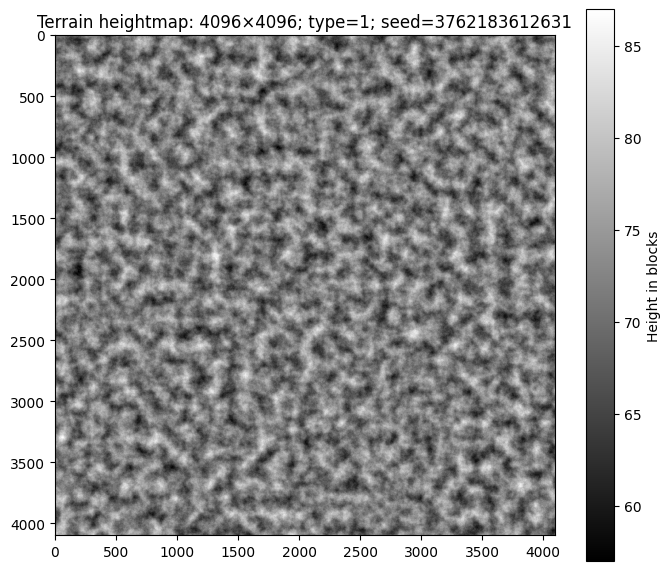

In [7]:
import numpy as np
import matplotlib.pyplot as plt
heights=np.fromfile('results/reference.bin',dtype=np.int32)
assert heights.size==WIDTH*HEIGHT, 'Run Version 1 at the selected size first.'
hmap=heights.reshape(HEIGHT,WIDTH)
d=np.zeros_like(hmap)
d[:,:-1]=np.maximum(d[:,:-1],np.abs(hmap[:,:-1]-hmap[:,1:]))
d[:-1,:]=np.maximum(d[:-1,:],np.abs(hmap[:-1,:]-hmap[1:,:]))
print('Height stats:',{'min':int(hmap.min()),'max':int(hmap.max()),'mean':float(hmap.mean()),
    'max_adjacent_difference':int(d.max()),'mean_adjacent_difference':float(d.mean())})
plt.figure(figsize=(7,6))
plt.imshow(hmap,cmap='gray',interpolation='nearest')
plt.title(f'Terrain heightmap: {WIDTH}×{HEIGHT}; type={TYPE}; seed={SEED}')
plt.colorbar(label='Height in blocks')
plt.tight_layout()
plt.savefig('results/terrain_heightmap.png',dpi=180)
plt.show()

In [8]:
# Optional rotatable 3D surface. Downsample for smooth interaction; not part of timing.
try:
    import plotly.graph_objects as go
    step=max(1,int(np.ceil(max(WIDTH,HEIGHT)/256)))
    sampled=hmap[::step,::step]
    fig=go.Figure(data=[go.Surface(z=sampled,colorscale='RdYlBu_r')])
    fig.update_layout(title='3D terrain preview (visualization only)',
                      scene=dict(xaxis_title='Column x',yaxis_title='Row z',zaxis_title='Height'),
                      width=750,height=600)
    fig.show()
except Exception as e:
    print('3D viewer skipped:',e)

### CPU comparisons: x86-64 scalar, XMM and YMM

These are extra comparisons requested by the rubric. The x86-64 program is a **compiler-generated scalar build, not handwritten assembly**. If your earlier SIMD course assignment has handwritten x86-64 code, insert its genuine benchmark results separately. AVX2 availability depends on the Colab CPU; compiling it may fail on CPUs without AVX2.

In [9]:
!g++ -O3 -std=c++17 -ffp-contract=off -fno-tree-vectorize -march=x86-64 -DX86_SCALAR src/terrain_cpu.cpp -o terrain_x86
!g++ -O3 -std=c++17 -ffp-contract=off -msse4.1 -DSIMD_LANES=4 src/terrain_cpu.cpp -o terrain_xmm
!g++ -O3 -std=c++17 -ffp-contract=off -mavx2 -DSIMD_LANES=8 src/terrain_cpu.cpp -o terrain_ymm
!./terrain_x86 --width {WIDTH} --height {HEIGHT} --type {TYPE} --octaves {OCTAVES} --seed {SEED} --repeats {REPEATS} --ref results/reference.bin --output '' | tee results/x86_4096.txt
!./terrain_xmm --width {WIDTH} --height {HEIGHT} --type {TYPE} --octaves {OCTAVES} --seed {SEED} --repeats {REPEATS} --ref results/reference.bin --output '' | tee results/xmm_4096.txt
!./terrain_ymm --width {WIDTH} --height {HEIGHT} --type {TYPE} --octaves {OCTAVES} --seed {SEED} --repeats {REPEATS} --ref results/reference.bin --output '' | tee results/ymm_4096.txt

VERSION=x86-64 non-SIMD compiled scalar (not handwritten assembly)
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
REPETITIONS=30 (plus 1 untimed warmup)
TIME_MS avg=2089.85273 min=1940.95011 max=2554.46197
CHECKSUM=1199217470 HEIGHT_MIN=57 HEIGHT_MAX=87
FIRST3=71,71,71
REFERENCE_SAVED=
CORRECTNESS=PASS max_height_diff=0 mismatched_columns=0
VERSION=CPU SIMD 4 lanes
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
REPETITIONS=30 (plus 1 untimed warmup)
TIME_MS avg=833.63575 min=752.01338 max=1126.57428
CHECKSUM=1199217470 HEIGHT_MIN=57 HEIGHT_MAX=87
FIRST3=71,71,71
REFERENCE_SAVED=
CORRECTNESS=PASS max_height_diff=0 mismatched_columns=0
VERSION=CPU SIMD 8 lanes
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
REPETITIONS=30 (plus 1 untimed warmup)
TIME_MS avg=631.53852 min=554.29697 max=881.35888
CHECKSUM=1199217470 HEIGHT_MIN=57 HEIGHT_MAX=87
FIRST3=71,71,71
REFERENCE_SAVED=
CORRECTNESS=PASS max_height_diff

## Common CUDA kernel and benchmarking driver

The `terrain_height_kernel` uses an explicit **grid-stride loop**. Different compile-time `VARIANT` values select the required managed-memory treatments, while using the identical math and thread mapping. This is fairer than comparing four entirely different terrain kernels. All variants output `CORRECTNESS=PASS/FAIL` against `results/reference.bin` and write measurements to `results/cuda_results.csv`.

**Memory treatment definition:** `page creation` means touching the managed output buffer once every 4 KiB on the CPU before prefetch. This is an experimental operational definition, not a CUDA API named “page creation.”

In [10]:
%%writefile src/terrain_cuda.cu
// Compile this same workload as FOUR DISTINCT executable variants using -DVARIANT=0..3.
// In all cases, the output is cudaMallocManaged unified memory.
// CUDA 0: no prefetch, no CPU page creation, no memory advice.
// CUDA 1: prefetch only.
// CUDA 2: touch one int in each page on CPU, then prefetch.
// CUDA 3: CPU page touch, preferred GPU location advice, then prefetch.
#include "terrain_math.hpp"
#include <cuda_runtime.h>
#include <algorithm>
#include <chrono>
#include <cstdlib>
#include <filesystem>
#include <fstream>
#include <iomanip>
#include <iostream>
#include <numeric>
#include <string>
#include <vector>

#ifndef VARIANT
#define VARIANT 0
#endif
#if VARIANT < 0 || VARIANT > 3
#error VARIANT must be 0..3
#endif

#define CUDA_CHECK(expr) do { \
    cudaError_t status=(expr); \
    if(status!=cudaSuccess) { \
        std::cerr<<"CUDA ERROR "<<#expr<<": "<<cudaGetErrorString(status) \
                 <<" at line "<<__LINE__<<"\n"; \
        std::exit(1); \
    } \
} while(0)

__constant__ uint8_t d_perm[512];

__global__ void terrain_height_kernel(int* output, TerrainParams p) {
    const long long first=(long long)blockIdx.x*blockDim.x+threadIdx.x;
    const long long stride=(long long)blockDim.x*gridDim.x;
    const long long n=(long long)p.width*p.height;
    for (long long i=first;i<n;i+=stride) {
        output[i]=terrain_height_at((int)i,p,d_perm);
    }
}

static const char* variant_name() {
#if VARIANT == 0
    return "CUDA Unified (no prefetch / no page creation / no advice)";
#elif VARIANT == 1
    return "CUDA Prefetch (no page creation / no advice)";
#elif VARIANT == 2
    return "CUDA Prefetch + CPU page creation (no advice)";
#else
    return "CUDA Prefetch + CPU page creation + mem advise";
#endif
}

int main(int argc, char** argv) {
    int w=4096,h=4096,type=1,octaves=0,repeats=30,block=256,x0=0,z0=0;
    uint64_t seed=3762183612631ULL;
    std::string reference="results/reference.bin";
    std::string csv="results/cuda_results.csv";
    for(int i=1;i<argc;++i) {
        std::string arg(argv[i]);
        if(i+1>=argc) {std::cerr<<"Missing value after "<<arg<<"\n";return 2;}
        std::string v(argv[++i]);
        if(arg=="--width") w=std::stoi(v);
        else if(arg=="--height") h=std::stoi(v);
        else if(arg=="--x0") x0=std::stoi(v);
        else if(arg=="--z0") z0=std::stoi(v);
        else if(arg=="--type") type=std::stoi(v);
        else if(arg=="--octaves") octaves=std::stoi(v);
        else if(arg=="--block") block=std::stoi(v);
        else if(arg=="--repeats") repeats=std::stoi(v);
        else if(arg=="--seed") seed=std::stoull(v);
        else if(arg=="--ref") reference=v;
        else if(arg=="--csv") csv=v;
        else {std::cerr<<"Unknown option: "<<arg<<"\n";return 2;}
    }
    if(w<1 || h<1 || (long long)w*h>200000000LL || type<0 || type>2 || repeats<30 ||
       octaves<0 || octaves>8 || (block!=256 && block!=512 && block!=1024)) {
        std::cerr<<"Invalid inputs. Allowed block sizes: 256/512/1024; repetitions >=30.\n";
        return 2;
    }
    const size_t n=(size_t)w*h, bytes=n*sizeof(int);
    TerrainParams p=make_params(w,h,type,octaves);
    p.x0=x0; p.z0=z0;
    std::vector<int> truth(n);
    {
        std::ifstream file(reference, std::ios::binary | std::ios::ate);
        if(!file || (size_t)file.tellg()!=bytes) {
            std::cerr<<"Missing or wrong-sized CPU reference: "<<reference<<" (expected "<<bytes<<" bytes)\n";
            return 2;
        }
        file.seekg(0);
        file.read(reinterpret_cast<char*>(truth.data()),static_cast<std::streamsize>(bytes));
        if(!file){std::cerr<<"Error reading CPU reference\n";return 2;}
    }
    int gpu=0, can_managed=0, can_concurrent=0;
    CUDA_CHECK(cudaGetDevice(&gpu));
    cudaDeviceProp prop{};
    CUDA_CHECK(cudaGetDeviceProperties(&prop,gpu));
    CUDA_CHECK(cudaDeviceGetAttribute(&can_managed,cudaDevAttrManagedMemory,gpu));
    CUDA_CHECK(cudaDeviceGetAttribute(&can_concurrent,cudaDevAttrConcurrentManagedAccess,gpu));
    if(!can_managed){std::cerr<<"GPU does not support CUDA managed allocations.\n";return 1;}
    uint8_t perm[512];make_permutation(seed,perm);
    CUDA_CHECK(cudaMemcpyToSymbol(d_perm,perm,sizeof(perm)));
    cudaStream_t stream{};
    CUDA_CHECK(cudaStreamCreate(&stream));
    cudaEvent_t start{}, stop{};
    CUDA_CHECK(cudaEventCreate(&start));
    CUDA_CHECK(cudaEventCreate(&stop));
    int* output=nullptr;
    const int max_blocks=std::max(1, prop.multiProcessorCount*32); // explicit cap; grid-stride handles full N
    const int blocks=std::min((long long)max_blocks, ((long long)n+block-1)/block);

    // ONE cold end-to-end operation: allocation + optional setup + one kernel + DtoH result.
    // CPU reference and permutation generation are deliberately outside this timing.
    auto total_start=std::chrono::steady_clock::now();
    CUDA_CHECK(cudaMallocManaged(&output,bytes));
#if VARIANT >= 2
    // "Page creation" is defined operationally here as first-touching each 4-KiB
    // segment from the CPU before launch. It is NOT a separate CUDA runtime API.
    for(size_t i=0;i<n;i+=1024) output[i]=0; // 1024 * sizeof(int) == 4096 bytes
    output[n-1]=0;
#endif
// CUDA 13 changed the Runtime API: prefetch/advice now take cudaMemLocation.
// Preserve the legacy integer device API for CUDA 12 and earlier.
#if VARIANT >= 1 && CUDART_VERSION >= 13000
    cudaMemLocation gpu_location{};
    gpu_location.type = cudaMemLocationTypeDevice;
    gpu_location.id = gpu;
#endif
#if VARIANT == 3
    #if CUDART_VERSION >= 13000
    CUDA_CHECK(cudaMemAdvise(output,bytes,cudaMemAdviseSetPreferredLocation,gpu_location));
    #else
    CUDA_CHECK(cudaMemAdvise(output,bytes,cudaMemAdviseSetPreferredLocation,gpu));
    #endif
#endif
#if VARIANT >= 1
    #if CUDART_VERSION >= 13000
    CUDA_CHECK(cudaMemPrefetchAsync(output,bytes,gpu_location,0,stream));
    #else
    CUDA_CHECK(cudaMemPrefetchAsync(output,bytes,gpu,stream));
    #endif
#endif
    CUDA_CHECK(cudaEventRecord(start,stream));
    terrain_height_kernel<<<blocks,block,0,stream>>>(output,p);
    CUDA_CHECK(cudaGetLastError());
    CUDA_CHECK(cudaEventRecord(stop,stream));
    CUDA_CHECK(cudaEventSynchronize(stop));
    float cold_ms=0.0f;
    CUDA_CHECK(cudaEventElapsedTime(&cold_ms,start,stop));
    std::vector<int> result(n);
    CUDA_CHECK(cudaMemcpy(result.data(),output,bytes,cudaMemcpyDefault));
    const auto total_stop=std::chrono::steady_clock::now();
    const double total_ms=std::chrono::duration<double,std::milli>(total_stop-total_start).count();

    // 30 warm, isolated GPU kernel runs; all times measured with GPU events.
    // Prefetch is a setup action, so it is not repeated before each warm kernel.
    std::vector<double> times;
    times.reserve(repeats);
    for(int r=0;r<repeats;++r) {
        CUDA_CHECK(cudaEventRecord(start,stream));
        terrain_height_kernel<<<blocks,block,0,stream>>>(output,p);
        CUDA_CHECK(cudaGetLastError());
        CUDA_CHECK(cudaEventRecord(stop,stream));
        CUDA_CHECK(cudaEventSynchronize(stop));
        float elapsed=0;
        CUDA_CHECK(cudaEventElapsedTime(&elapsed,start,stop));
        times.push_back(elapsed);
    }
    CUDA_CHECK(cudaMemcpy(result.data(),output,bytes,cudaMemcpyDefault));
    int max_diff=0;
    size_t mismatches=0;
    long long checksum=0;
    for(size_t i=0;i<n;++i) {
        int diff=std::abs(result[i]-truth[i]);
        max_diff=std::max(max_diff,diff);
        if(diff)++mismatches;
        checksum+=result[i];
    }
    // Proposal's tolerance: difference <=1, and <=0.01% of columns differ.
    const double mismatch_pct=100.0*(double)mismatches/(double)n;
    const bool pass=(max_diff<=1 && mismatch_pct<=0.01);
    const double mean=std::accumulate(times.begin(),times.end(),0.0)/times.size();
    const auto [mn,mx]=std::minmax_element(times.begin(),times.end());
    std::cout<<std::fixed<<std::setprecision(5)
             <<"VERSION="<<variant_name()<<"\n"
             <<"GPU="<<prop.name<<" SMs="<<prop.multiProcessorCount
             <<" managed="<<can_managed<<" concurrent_managed="<<can_concurrent<<"\n"
             <<"INPUT width="<<w<<" height="<<h<<" x0="<<x0<<" z0="<<z0<<" type="<<type<<" octaves="<<p.octaves<<" seed="<<seed<<"\n"
             <<"GRID blocks="<<blocks<<" threads_per_block="<<block<<" grid_stride=YES\n"
             <<"REPETITIONS="<<repeats<<" (plus 1 cold launch)\n"
             <<"COLD_KERNEL_MS="<<cold_ms<<" E2E_ONE_OPERATION_MS="<<total_ms<<"\n"
             <<"WARM_KERNEL_MS avg="<<mean<<" min="<<*mn<<" max="<<*mx<<"\n"
             <<"CHECKSUM="<<checksum<<" FIRST3="<<result[0]<<","<<result[std::min<size_t>(1,n-1)]<<","<<result[std::min<size_t>(2,n-1)]<<"\n"
             <<"CORRECTNESS="<<(pass?"PASS":"FAIL")<<" max_height_diff="<<max_diff
             <<" mismatched_columns="<<mismatches<<" mismatch_pct="<<mismatch_pct<<"\n";
    if(!csv.empty()) {
        std::filesystem::path path(csv);
        if(!path.parent_path().empty()) std::filesystem::create_directories(path.parent_path());
        bool header=!std::filesystem::exists(csv) || std::filesystem::file_size(csv)==0;
        std::ofstream f(csv,std::ios::app);
        if(!f){std::cerr<<"Could not open CSV "<<csv<<"\n";return 1;}
        if(header) f<<"variant,width,height,x0,z0,type,octaves,seed,block,blocks,repeats,warm_avg_ms,warm_min_ms,warm_max_ms,cold_kernel_ms,e2e_once_ms,checksum,max_diff,mismatch_count,mismatch_pct,pass,gpu\n";
        f<<VARIANT<<","<<w<<","<<h<<","<<x0<<","<<z0<<","<<type<<","<<p.octaves<<","<<seed<<","<<block<<","<<blocks<<","<<repeats<<","<<mean<<","<<*mn<<","<<*mx<<","<<cold_ms<<","<<total_ms<<","<<checksum<<","<<max_diff<<","<<mismatches<<","<<mismatch_pct<<","<<(pass?1:0)<<",\""<<prop.name<<"\"\n";
    }
    CUDA_CHECK(cudaFree(output));
    CUDA_CHECK(cudaEventDestroy(start));CUDA_CHECK(cudaEventDestroy(stop));
    CUDA_CHECK(cudaStreamDestroy(stream));
    return pass?0:3;
}


Writing src/terrain_cuda.cu


> **Compatibility fix (CUDA 12 / CUDA 13):** NVIDIA changed the `cudaMemPrefetchAsync` and `cudaMemAdvise` signatures in CUDA 13. The shared driver above automatically chooses the correct API using `CUDART_VERSION`. If you used an older notebook, **re-run the `%%writefile src/terrain_cuda.cu` cell before compiling CUDA versions 2–5**. Real benchmark numbers must be collected from the GPU.


## CUDA compiler and GPU preflight check

Run this diagnostic before versions 2–5. It checks the **actual connected kernel**, independently verifies GPU access, and searches common CUDA Toolkit paths for `nvcc`. A T4 selection in the menu does not guarantee a GPU has been assigned to the current session.


In [11]:
# GPU and CUDA toolkit check — distinguishes GPU allocation from missing PATH.
import os, shutil, subprocess
from pathlib import Path

print('Connected Python:', __import__('sys').executable)
print('COLAB_GPU setting:', os.getenv('COLAB_GPU', '<unset>'))
print('GPU device node:', 'present' if Path('/dev/nvidia0').exists() else 'missing')

# Some runtimes install nvcc without adding its directory to PATH.
def find_binary(name, candidates):
    found = shutil.which(name)
    if found:
        return found
    for candidate in candidates:
        if Path(candidate).is_file():
            return candidate
    return None

smi = find_binary('nvidia-smi', ['/usr/bin/nvidia-smi', '/usr/local/bin/nvidia-smi', '/var/lib/nvidia/bin/nvidia-smi'])
nvcc = find_binary('nvcc', ['/usr/local/cuda/bin/nvcc', '/opt/cuda/bin/nvcc', '/usr/local/cuda-12.8/bin/nvcc', '/usr/local/cuda-12.6/bin/nvcc', '/usr/local/cuda-12.5/bin/nvcc', '/usr/local/cuda-12.4/bin/nvcc'])
print('nvidia-smi path:', smi or 'NOT FOUND')
print('nvcc path:', nvcc or 'NOT FOUND')

has_gpu = False
if smi:
    proc = subprocess.run([smi], text=True, capture_output=True)
    print('nvidia-smi exit code:', proc.returncode)
    print((proc.stdout + proc.stderr)[:5000])
    has_gpu = proc.returncode == 0

try:
    import torch
    torch_gpu = torch.cuda.is_available()
    print('PyTorch CUDA available:', torch_gpu)
    if torch_gpu:
        print('Detected GPU:', torch.cuda.get_device_name(0))
        has_gpu = True
except ImportError:
    print('PyTorch not installed; skipping independent GPU test.')
except Exception as e:
    print('PyTorch GPU test failed:', str(e)[:400])

if nvcc:
    os.environ['PATH'] = str(Path(nvcc).parent) + os.pathsep + os.environ.get('PATH', '')
    print('Added CUDA compiler directory to PATH when needed.')

if not has_gpu:
    raise RuntimeError('The CONNECTED notebook kernel cannot access an NVIDIA GPU. Selecting T4 is not enough if Colab did not allocate/connect to it, or if this is a local/other runtime. Open a NEW blank notebook at colab.new, select T4, connect, and run !nvidia-smi there. If it also fails, this is a runtime availability/connection issue, not a terrain-code error.')
if not nvcc:
    raise RuntimeError('An NVIDIA GPU is available, but the nvcc compiler is not installed/found in this runtime. Check the CUDA Toolkit installation; the project CUDA variants require nvcc.')
print('PREFLIGHT PASS: CUDA GPU and nvcc compiler are ready. Run Version 2 through Version 5.')


Connected Python: /usr/bin/python3
COLAB_GPU setting: 1
GPU device node: present
nvidia-smi path: /opt/bin/nvidia-smi
nvcc path: /usr/local/cuda/bin/nvcc
nvidia-smi exit code: 0
Sun Nov  8 12:48:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8              9W /   70W |       0MiB

## Version 2 — Unified memory — no prefetch, no pages, no advise

This version has its **own source/compile/run cells** and uses the common `terrain_height_kernel` with grid-stride scheduling. It performs one **cold** launch and **30 warm measured** kernel launches with CUDA events. Also reports one-operation E2E including setup and output transfer; compares all W × H heights to sequential C++ reference.

In [12]:
%%writefile src/cuda_unified.cu
#define VARIANT 0
#include "terrain_cuda.cu"


Writing src/cuda_unified.cu


In [13]:
# Fail-fast compile and execution: display the actual nvcc error, if any.
import subprocess, shutil
from pathlib import Path
name='cuda_unified'
compiler=shutil.which('nvcc')
if not compiler:
    raise RuntimeError('nvcc not available. Enable GPU runtime, reconnect, and run the CUDA preflight cell.')
compile_cmd=[compiler,'-O3','-std=c++17','--fmad=false',f'src/{name}.cu','-o',name]
p=subprocess.run(compile_cmd,text=True,capture_output=True)
print('COMPILE:', 'PASS' if p.returncode==0 else 'FAIL',name)
if p.stdout: print(p.stdout)
if p.stderr: print(p.stderr)
if p.returncode != 0:
    raise RuntimeError(f'CUDA compilation failed for {name}. Inspect nvcc messages above; the benchmark cannot run yet.')
run_cmd=['./'+name,'--width',str(WIDTH),'--height',str(HEIGHT),'--type',str(TYPE),
         '--octaves',str(OCTAVES),'--seed',str(SEED),'--block',str(BLOCK),
         '--repeats',str(REPEATS),'--ref','results/reference.bin','--csv','results/cuda_results.csv']
p=subprocess.run(run_cmd,text=True,capture_output=True)
print(p.stdout)
if p.stderr: print(p.stderr)
Path(f'results/{name}_{BLOCK}.txt').write_text(p.stdout+'\n'+p.stderr)
if p.returncode != 0:
    raise RuntimeError(f'CUDA program {name} returned error {p.returncode}. Inspect output above.')
assert 'CORRECTNESS=PASS' in p.stdout, f'CUDA result from {name} did not report PASS.'


COMPILE: PASS cuda_unified
VERSION=CUDA Unified (no prefetch / no page creation / no advice)
GPU=Tesla T4 SMs=40 managed=1 concurrent_managed=1
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
GRID blocks=1280 threads_per_block=256 grid_stride=YES
REPETITIONS=30 (plus 1 cold launch)
COLD_KERNEL_MS=10.89440 E2E_ONE_OPERATION_MS=57.82715
WARM_KERNEL_MS avg=2.94164 min=2.48682 max=3.04477
CHECKSUM=1199217470 FIRST3=71,71,71
CORRECTNESS=PASS max_height_diff=0 mismatched_columns=0 mismatch_pct=0.00000



## Version 3 — Unified memory + prefetch, no page creation, no advise

This version has its **own source/compile/run cells** and uses the common `terrain_height_kernel` with grid-stride scheduling. It performs one **cold** launch and **30 warm measured** kernel launches with CUDA events. Also reports one-operation E2E including setup and output transfer; compares all W × H heights to sequential C++ reference.

In [14]:
%%writefile src/cuda_prefetch.cu
#define VARIANT 1
#include "terrain_cuda.cu"


Writing src/cuda_prefetch.cu


In [15]:
# Fail-fast compile and execution: display the actual nvcc error, if any.
import subprocess, shutil
from pathlib import Path
name='cuda_prefetch'
compiler=shutil.which('nvcc')
if not compiler:
    raise RuntimeError('nvcc not available. Enable GPU runtime, reconnect, and run the CUDA preflight cell.')
compile_cmd=[compiler,'-O3','-std=c++17','--fmad=false',f'src/{name}.cu','-o',name]
p=subprocess.run(compile_cmd,text=True,capture_output=True)
print('COMPILE:', 'PASS' if p.returncode==0 else 'FAIL',name)
if p.stdout: print(p.stdout)
if p.stderr: print(p.stderr)
if p.returncode != 0:
    raise RuntimeError(f'CUDA compilation failed for {name}. Inspect nvcc messages above; the benchmark cannot run yet.')
run_cmd=['./'+name,'--width',str(WIDTH),'--height',str(HEIGHT),'--type',str(TYPE),
         '--octaves',str(OCTAVES),'--seed',str(SEED),'--block',str(BLOCK),
         '--repeats',str(REPEATS),'--ref','results/reference.bin','--csv','results/cuda_results.csv']
p=subprocess.run(run_cmd,text=True,capture_output=True)
print(p.stdout)
if p.stderr: print(p.stderr)
Path(f'results/{name}_{BLOCK}.txt').write_text(p.stdout+'\n'+p.stderr)
if p.returncode != 0:
    raise RuntimeError(f'CUDA program {name} returned error {p.returncode}. Inspect output above.')
assert 'CORRECTNESS=PASS' in p.stdout, f'CUDA result from {name} did not report PASS.'


COMPILE: PASS cuda_prefetch
VERSION=CUDA Prefetch (no page creation / no advice)
GPU=Tesla T4 SMs=40 managed=1 concurrent_managed=1
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
GRID blocks=1280 threads_per_block=256 grid_stride=YES
REPETITIONS=30 (plus 1 cold launch)
COLD_KERNEL_MS=3.41674 E2E_ONE_OPERATION_MS=56.95720
WARM_KERNEL_MS avg=3.26327 min=2.80160 max=3.36928
CHECKSUM=1199217470 FIRST3=71,71,71
CORRECTNESS=PASS max_height_diff=0 mismatched_columns=0 mismatch_pct=0.00000



## Version 4 — Unified memory + prefetch + CPU page creation, no advise

This version has its **own source/compile/run cells** and uses the common `terrain_height_kernel` with grid-stride scheduling. It performs one **cold** launch and **30 warm measured** kernel launches with CUDA events. Also reports one-operation E2E including setup and output transfer; compares all W × H heights to sequential C++ reference.

In [16]:
%%writefile src/cuda_pages.cu
#define VARIANT 2
#include "terrain_cuda.cu"


Writing src/cuda_pages.cu


In [17]:
# Fail-fast compile and execution: display the actual nvcc error, if any.
import subprocess, shutil
from pathlib import Path
name='cuda_pages'
compiler=shutil.which('nvcc')
if not compiler:
    raise RuntimeError('nvcc not available. Enable GPU runtime, reconnect, and run the CUDA preflight cell.')
compile_cmd=[compiler,'-O3','-std=c++17','--fmad=false',f'src/{name}.cu','-o',name]
p=subprocess.run(compile_cmd,text=True,capture_output=True)
print('COMPILE:', 'PASS' if p.returncode==0 else 'FAIL',name)
if p.stdout: print(p.stdout)
if p.stderr: print(p.stderr)
if p.returncode != 0:
    raise RuntimeError(f'CUDA compilation failed for {name}. Inspect nvcc messages above; the benchmark cannot run yet.')
run_cmd=['./'+name,'--width',str(WIDTH),'--height',str(HEIGHT),'--type',str(TYPE),
         '--octaves',str(OCTAVES),'--seed',str(SEED),'--block',str(BLOCK),
         '--repeats',str(REPEATS),'--ref','results/reference.bin','--csv','results/cuda_results.csv']
p=subprocess.run(run_cmd,text=True,capture_output=True)
print(p.stdout)
if p.stderr: print(p.stderr)
Path(f'results/{name}_{BLOCK}.txt').write_text(p.stdout+'\n'+p.stderr)
if p.returncode != 0:
    raise RuntimeError(f'CUDA program {name} returned error {p.returncode}. Inspect output above.')
assert 'CORRECTNESS=PASS' in p.stdout, f'CUDA result from {name} did not report PASS.'


COMPILE: PASS cuda_pages
VERSION=CUDA Prefetch + CPU page creation (no advice)
GPU=Tesla T4 SMs=40 managed=1 concurrent_managed=1
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
GRID blocks=1280 threads_per_block=256 grid_stride=YES
REPETITIONS=30 (plus 1 cold launch)
COLD_KERNEL_MS=2.92029 E2E_ONE_OPERATION_MS=75.01006
WARM_KERNEL_MS avg=2.86784 min=2.32909 max=2.92045
CHECKSUM=1199217470 FIRST3=71,71,71
CORRECTNESS=PASS max_height_diff=0 mismatched_columns=0 mismatch_pct=0.00000



## Version 5 — Unified memory + prefetch + CPU page creation + mem advise

This version has its **own source/compile/run cells** and uses the common `terrain_height_kernel` with grid-stride scheduling. It performs one **cold** launch and **30 warm measured** kernel launches with CUDA events. Also reports one-operation E2E including setup and output transfer; compares all W × H heights to sequential C++ reference.

In [18]:
%%writefile src/cuda_advice.cu
#define VARIANT 3
#include "terrain_cuda.cu"


Writing src/cuda_advice.cu


In [19]:
# Fail-fast compile and execution: display the actual nvcc error, if any.
import subprocess, shutil
from pathlib import Path
name='cuda_advice'
compiler=shutil.which('nvcc')
if not compiler:
    raise RuntimeError('nvcc not available. Enable GPU runtime, reconnect, and run the CUDA preflight cell.')
compile_cmd=[compiler,'-O3','-std=c++17','--fmad=false',f'src/{name}.cu','-o',name]
p=subprocess.run(compile_cmd,text=True,capture_output=True)
print('COMPILE:', 'PASS' if p.returncode==0 else 'FAIL',name)
if p.stdout: print(p.stdout)
if p.stderr: print(p.stderr)
if p.returncode != 0:
    raise RuntimeError(f'CUDA compilation failed for {name}. Inspect nvcc messages above; the benchmark cannot run yet.')
run_cmd=['./'+name,'--width',str(WIDTH),'--height',str(HEIGHT),'--type',str(TYPE),
         '--octaves',str(OCTAVES),'--seed',str(SEED),'--block',str(BLOCK),
         '--repeats',str(REPEATS),'--ref','results/reference.bin','--csv','results/cuda_results.csv']
p=subprocess.run(run_cmd,text=True,capture_output=True)
print(p.stdout)
if p.stderr: print(p.stderr)
Path(f'results/{name}_{BLOCK}.txt').write_text(p.stdout+'\n'+p.stderr)
if p.returncode != 0:
    raise RuntimeError(f'CUDA program {name} returned error {p.returncode}. Inspect output above.')
assert 'CORRECTNESS=PASS' in p.stdout, f'CUDA result from {name} did not report PASS.'


COMPILE: PASS cuda_advice
VERSION=CUDA Prefetch + CPU page creation + mem advise
GPU=Tesla T4 SMs=40 managed=1 concurrent_managed=1
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
GRID blocks=1280 threads_per_block=256 grid_stride=YES
REPETITIONS=30 (plus 1 cold launch)
COLD_KERNEL_MS=2.47146 E2E_ONE_OPERATION_MS=78.55296
WARM_KERNEL_MS avg=2.40666 min=2.40026 max=2.45101
CHECKSUM=1199217470 FIRST3=71,71,71
CORRECTNESS=PASS max_height_diff=0 mismatched_columns=0 mismatch_pct=0.00000



## Experiment: block-size sensitivity (256, 512, 1024)

Runs **30 timed launches per block-size and per CUDA variant**. The code below collects 12 additional benchmark rows for the main `2^24` setting. Note that our grid cap is `32 × number_of_SMs` and is not the architectural maximum grid dimension.

In [20]:
# Stop immediately if CUDA compilation was unsuccessful.
from pathlib import Path
variants=['cuda_unified','cuda_prefetch','cuda_pages','cuda_advice']
missing=[name for name in variants if not Path(name).is_file()]
if missing:
    raise RuntimeError('Cannot run block-size tests. Missing CUDA executables: '+', '.join(missing)+'. Run and fix Version 2–5 compilation cells first.')
import subprocess
for block_size in (256,512,1024):
    for name in variants:
        cmd=['./'+name,'--width',str(WIDTH),'--height',str(HEIGHT),'--type',str(TYPE),
             '--octaves',str(OCTAVES),'--seed',str(SEED),'--block',str(block_size),
             '--repeats',str(REPEATS),'--ref','results/reference.bin','--csv','results/cuda_results.csv']
        print('\n',name,'block=',block_size,flush=True)
        try:
            out=subprocess.run(cmd,check=True,text=True,capture_output=True)
            print(out.stdout)
            Path(f'results/{name}_{block_size}.txt').write_text(out.stdout)
        except (FileNotFoundError,subprocess.CalledProcessError) as error:
            print('UNAVAILABLE/FAILED:',error)
            if isinstance(error,subprocess.CalledProcessError): print(error.stderr)
            print('This setting was not measured; report as unsupported/failed and continue.')


 cuda_unified block= 256
VERSION=CUDA Unified (no prefetch / no page creation / no advice)
GPU=Tesla T4 SMs=40 managed=1 concurrent_managed=1
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
GRID blocks=1280 threads_per_block=256 grid_stride=YES
REPETITIONS=30 (plus 1 cold launch)
COLD_KERNEL_MS=10.03302 E2E_ONE_OPERATION_MS=57.02869
WARM_KERNEL_MS avg=2.06571 min=2.04182 max=2.08896
CHECKSUM=1199217470 FIRST3=71,71,71
CORRECTNESS=PASS max_height_diff=0 mismatched_columns=0 mismatch_pct=0.00000


 cuda_prefetch block= 256
VERSION=CUDA Prefetch (no page creation / no advice)
GPU=Tesla T4 SMs=40 managed=1 concurrent_managed=1
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
GRID blocks=1280 threads_per_block=256 grid_stride=YES
REPETITIONS=30 (plus 1 cold launch)
COLD_KERNEL_MS=2.10534 E2E_ONE_OPERATION_MS=62.50724
WARM_KERNEL_MS avg=2.07411 min=2.06445 max=2.08486
CHECKSUM=1199217470 FIRST3=71,71,71
CORRECTNESS=PASS max_height_diff=0 

## RQ1 — CPU/GPU crossover across world sizes (optional extension)

The group proposal also asks **at what size GPU end-to-end beats sequential C++**. The main rubric explicitly requests `2^24`, so the cell below adds *separate* benchmark rows for 16, 64, 256, and 1024 square worlds, all at 30 runs. It creates each size's CPU reference and runs each CUDA variant with a 256-thread block. Keep CPU/GPU measured on the **same runtime**.

In [21]:
RUN_CROSSOVER = False   # switch to True after the main assignment runs successfully
if RUN_CROSSOVER:
    import csv
    for side in (16,64,256,1024):
        reference=f'results/reference_{side}.bin'
        cpu_cmd=['./terrain_cpu','--width',str(side),'--height',str(side),
                 '--type',str(TYPE),'--octaves',str(OCTAVES), '--seed',str(SEED),
                 '--repeats',str(REPEATS),'--output',reference]
        print(f'\nCPU side={side}')
        print(subprocess.run(cpu_cmd,check=True,capture_output=True,text=True).stdout)
        for name in variants:
            gpu_cmd=['./'+name,'--width',str(side),'--height',str(side),
                    '--type',str(TYPE),'--octaves',str(OCTAVES),'--seed',str(SEED),
                    '--block','256','--repeats',str(REPEATS),'--ref',reference,
                    '--csv','results/cuda_results.csv']
            out=subprocess.run(gpu_cmd,check=True,capture_output=True,text=True)
            print(name, out.stdout.split('CORRECTNESS=')[-1].strip())
else:
    print('Optional crossover sweep skipped. Set RUN_CROSSOVER=True to run.')

Optional crossover sweep skipped. Set RUN_CROSSOVER=True to run.


## Optional edge-case correctness tests from the proposal

Extra 1×1, 3×3, 15×17, 255×257 and distant-origin tests check grid-stride bounds, reproducibility and numerical agreement. These are not part of the measured `2^24` timing table. Turn this on once the main cases pass.

In [22]:
RUN_EDGE_CASE_TESTS=False  # set True to verify both seeds, all terrain types, and non-multiple dimensions
if RUN_EDGE_CASE_TESTS:
    edge_sizes=((1,1),(3,3),(15,17),(255,257))
    for test_seed in (3762183612631,42):
        for terrain_id in (0,1,2):
            for xorig,zorig in ((0,0),(-5000,3000)):
                for ww,hh in edge_sizes:
                    p=['--width',str(ww),'--height',str(hh),'--type',str(terrain_id),
                       '--seed',str(test_seed),'--x0',str(xorig),'--z0',str(zorig),'--repeats','30']
                    ref='results/edge_reference.bin'
                    subprocess.run(['./terrain_cpu',*p,'--output',ref],capture_output=True,text=True,check=True)
                    for binary in variants:
                        out=subprocess.run(['./'+binary,*p,'--block','256','--ref',ref,'--csv',''],
                                           capture_output=True,text=True,check=True)
                        if 'CORRECTNESS=PASS' not in out.stdout: raise RuntimeError(binary+' failed')
    print('All edge-case CUDA comparisons passed.')
else:
    print('Optional edge-case sweep skipped.')

Optional edge-case sweep skipped.


## Nsight Systems (nsys) — all four CUDA variants

Profile each version and save a real `.nsys-rep`, plus the `cuda_gpu_kern_sum` report. The summary shows the kernels that executed; use screenshots from the profiler to meet the rubric. Some Colab instances do not include `nsys` or do not permit all profiling features. Do **not** invent profiler results or combine profiles from other machines with the Colab timings.

In [23]:
nsys=shutil.which('nsys')
if nsys is None:
    print('nsys unavailable in this environment. Profile on the group NVIDIA computer or install a supported Nsight Systems package.')
else:
    for name in variants:
        report=f'profiles/nsys_{name}'
        cmd=[nsys,'profile','--trace=cuda,nvtx','--sample=none','--cpuctxsw=none',
             '-o',report,'--force-overwrite=true','./'+name,'--width',str(WIDTH),
             '--height',str(HEIGHT),'--type',str(TYPE),'--octaves',str(OCTAVES),
             '--seed',str(SEED),'--block',str(BLOCK),'--repeats',str(REPEATS),
             '--ref','results/reference.bin','--csv','']
        print('Profiling',name)
        p=subprocess.run(cmd,text=True,capture_output=True)
        print((p.stdout+'\n'+p.stderr)[-2000:])
        if p.returncode==0:
            stats=subprocess.run([nsys,'stats','--report','cuda_gpu_kern_sum',report+'.nsys-rep'],
                                 text=True,capture_output=True)
            Path(report+'_summary.txt').write_text(stats.stdout+'\n'+stats.stderr)
            print(stats.stdout[-1500:])
        else:
            print('NSYS FAILED: use a profiler-supported machine and document failure.')

Profiling cuda_unified
VERSION=CUDA Unified (no prefetch / no page creation / no advice)
GPU=Tesla T4 SMs=40 managed=1 concurrent_managed=1
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
GRID blocks=1280 threads_per_block=256 grid_stride=YES
REPETITIONS=30 (plus 1 cold launch)
COLD_KERNEL_MS=11.35133 E2E_ONE_OPERATION_MS=78.34394
WARM_KERNEL_MS avg=3.70318 min=3.69181 max=3.71622
CHECKSUM=1199217470 FIRST3=71,71,71
CORRECTNESS=PASS max_height_diff=0 mismatched_columns=0 mismatch_pct=0.00000
Generating '/tmp/nsys-report-7764.qdstrm'

[1/1] [0%                          ] nsys_cuda_unified.nsys-rep
[1/1] [0%                          ] nsys_cuda_unified.nsys-rep
[1/1] [============55%             ] nsys_cuda_unified.nsys-rep
[1/1] [=============59%            ] nsys_cuda_unified.nsys-rep
[1/1] [==============63%           ] nsys_cuda_unified.nsys-rep
[1/1] [================70%         ] nsys_cuda_unified.nsys-rep
[1/1] [==================77%       ] nsys_cuda_un

## Nsight Compute (ncu) — inspect one steady-state kernel for each variant

`--launch-skip 1 --launch-count 1` avoids turning the full 30-run experiment into 30 extremely slow instrumented launches. **Measured benchmark times come from the unprofiled CUDA events**, not profiler-replay timings. Some managed environments deny access to GPU performance counters.

In [24]:
ncu=shutil.which('ncu')
if ncu is None:
    print('ncu unavailable. Collect ncu runs on a supported NVIDIA workstation and add real evidence.')
else:
    for name in variants:
        cmd=[ncu,'--set','basic','--launch-skip','1','--launch-count','1',
             '-o',f'profiles/ncu_{name}','--force-overwrite','./'+name,
             '--width',str(WIDTH),'--height',str(HEIGHT),'--type',str(TYPE),
             '--octaves',str(OCTAVES),'--seed',str(SEED),'--block',str(BLOCK),
             '--repeats',str(REPEATS),'--ref','results/reference.bin','--csv','']
        print('Profiling',name)
        p=subprocess.run(cmd,text=True,capture_output=True)
        print((p.stdout+'\n'+p.stderr)[-2000:])
        if p.returncode!=0:
            print('NCU FAILED: GPU performance counters may be restricted; try the local NVIDIA machine.')

Profiling cuda_unified
==PROF== Connected to process 2432 (/content/cuda_unified)
==PROF== Profiling "terrain_height_kernel" - 0 (1/1): 0%....50%....100% - 10 passes
VERSION=CUDA Unified (no prefetch / no page creation / no advice)
GPU=Tesla T4 SMs=40 managed=1 concurrent_managed=1
INPUT width=4096 height=4096 x0=0 z0=0 type=1 octaves=4 seed=3762183612631
GRID blocks=1280 threads_per_block=256 grid_stride=YES
REPETITIONS=30 (plus 1 cold launch)
COLD_KERNEL_MS=20.00486 E2E_ONE_OPERATION_MS=78.93426
WARM_KERNEL_MS avg=85.10759 min=2.61939 max=2476.00024
CHECKSUM=1199217470 FIRST3=71,71,71
CORRECTNESS=PASS max_height_diff=0 mismatched_columns=0 mismatch_pct=0.00000
==PROF== Disconnected from process 2432
==PROF== Report: /content/profiles/ncu_cuda_unified.ncu-rep


Profiling cuda_prefetch
==PROF== Connected to process 2488 (/content/cuda_prefetch)
==PROF== Profiling "terrain_height_kernel" - 0 (1/1): 0%....50%....100% - 10 passes
VERSION=CUDA Prefetch (no page creation / no advice)
GPU=Te

## Write real collected numbers into the GitHub README (inline)

The report is **in GitHub `README.md` itself**, not linked to a separate PDF. The next two cells write the README template and update its **measured-results section from real logs and CSV**. Empty rows remain explicitly unmeasured. Then add **actual screenshots** of C/CUDA outputs and `nsys` profiles to `screenshots/` and embed them in `README.md`. Finally upload and share this notebook in your public/instructor-accessible GitHub repo and put its actual Colab link in README. Do not add fake figures.

In [25]:
%%writefile README.md
# CPU vs. GPU Terrain Generation: Measuring When CUDA Beats Sequential C++

**CEPARCO — Deep Dive: CUDA Concept and Programming (group assignment)**

> **Submission status:** Working CPU implementations and CUDA source are provided. **GPU performance data, Nsight traces, screenshots, and final measured conclusions MUST be generated on your actual CUDA-enabled machine before submitting.** No GPU measurements are invented in this repository.

## 0. Group, specifications, and AI disclosure

**Group members (verify against current roster):** Matthew Fabregas; Kane Ibanez; Bowen Li; Jat Teoxon.

**Specification:** Create a deterministic Minecraft-inspired 2D heightmap using seeded 2D improved-Perlin-style gradient noise and fractal Brownian motion. Every terrain column `(x,z)` is independent, so CPU scalar, CPU SIMD, and CUDA SIMT execute the **same height calculation** with different parallelization strategies. No caves, structures, villages, or rendering costs are included in the timing. The main input is `4096 × 4096 = 2^24` output heights.

**Documented initialization:** A CPU `std::mt19937_64` seeded by **3762183612631** shuffles values 0–255 using Fisher–Yates. The resulting 256-byte permutation is duplicated to 512 bytes and copied to CUDA constant memory. Height `i` uses `x=i%W` and `z=i/W`, with world origin `(0,0)`. The height-output array is fully overwritten by the generator; no random input vector is needed. Additional test seed: `42`. For small tests also use `17×5` and `255×257` non-multiple sizes.

**Terrain types:**

| Type | Base height | Amplitude | Base frequency | Octaves | Ridged |
|---|---:|---:|---:|---:|---|
| Plains (0) | 64 | 8 | 0.004 | 2 | no |
| Hilly (1, default) | 72 | 24 | 0.008 | 4 | no |
| Mountains (2) | 100 | 90 | 0.004 | 6 | yes |

Noise uses `fade(t)=6t^5−15t^4+10t^3`, gradient hashes, bilinear interpolation, octave amplitude 0.5 and frequency factor 2. Heights are `floor(B+A*noise)` and clipped to `[-64,319]`, as in the approved proposal. Both CPU and GPU use float arithmetic; GPU is built with `--fmad=false` for closer numerical reproducibility.

**AI usage declaration (edit to reflect actual contributions):** ChatGPT helped draft the C++/CUDA notebook scaffold, benchmark script, explanations, and initial report structure. Group members must review and test all code, generate real profiler evidence, complete the measured analysis, and take responsibility for the submitted results. Do not claim the measurements below were collected until you actually run them.

## 1. Implementations and experimental treatment

| Report case | Implementation | Data movement and setup |
|---|---|---|
| C | sequential C++ scalar, one height per iteration | normal CPU memory |
| x86-64 | separately built non-SIMD x86-64 C++ executable | **compiler-generated**, not handwritten assembly |
| x86-64 XMM | XMM SIMD (4 `float` lanes, SSE4.1) | hash table gathered per lane, vectorized arithmetic |
| x86-64 YMM | YMM SIMD (8 `float` lanes, AVX2) | hash table gathered per lane, vectorized arithmetic |
| CUDA Unified | `cudaMallocManaged`, grid-stride | no prefetch, no CPU page touch, no memory advise |
| CUDA Prefetch | `cudaMallocManaged`, grid-stride | `cudaMemPrefetchAsync`, no CPU page touch, no memory advise |
| CUDA Prefetch + page creation | `cudaMallocManaged`, grid-stride | **CPU first-touch every 4096-byte segment** followed by prefetch; no advise |
| CUDA Prefetch + page creation + mem advise | same as above | plus `cudaMemAdviseSetPreferredLocation(...GPU)` |

**Important interpretation:** “Page creation” is **not a named CUDA runtime API**. For this experiment we define it explicitly as CPU first-touch of each 4096-byte segment before GPU prefetch. Actual physical page sizes and Unified Memory migration policies are hardware/OS-dependent. We are deliberately altering allocation residency between treatments, so interpret differences carefully.

All CUDA variants run the same `terrain_height_kernel` with a **grid-stride loop**. Blocks tested: **256, 512, and 1024** threads per block. The grid is capped at `32 × SM_count` blocks to avoid an excessive launch grid; the grid-stride loop handles any remaining columns. This is an experimental cap, **not** a claim that it is the GPU's physical maximum block count.

**Measurement definition:** All CPU executables perform 1 untimed warm-up and 30 timed full-heightmap generations with `std::chrono`. Each CUDA variant performs 1 cold launch and 30 further **warm** event-timed kernel launches. We record `warm avg/min/max`, first/cold-kernel time, and **one-operation end-to-end (E2E)** wall-clock time for allocation + variant setup + first launch + transfer to host. Timing and correctness are **separate**: the host CPU reference generation is outside the GPU total. Prefetch and page-touch operations affect the cold and E2E measurements but are intentionally not repeated for each warm launch. Thus warm kernel time alone is not an adequate measure of prefetch benefits.

**Correctness rule:** compare output against the C++ reference from the same size, seed and terrain type. `PASS` requires `max absolute height difference ≤1` and `≤0.01%` differing columns (proposal's rule). Report mismatches and checksums. Any CUDA command exits with an error on `FAIL`.

## 2. Program output screenshots — to be captured from actual runs

Insert images directly **in this README**, not as links to an external report. Screenshots should show the `VERSION`, `TIME_MS` or `WARM_KERNEL_MS`, `CORRECTNESS`, and `REPETITIONS=30` lines. Fill these file names by taking and committing actual screenshots.

| Case | Evidence |
|---|---|
| C (reference) | _TODO: screenshot of CPU reference output with execution time_ |
| x86-64 scalar (compiled) | _TODO: screenshot with PASS and time_ |
| XMM | _TODO: screenshot with PASS and time_ |
| YMM | _TODO: screenshot with PASS and time_ |
| CUDA Unified | _TODO: screenshot with PASS and 30-run time_ |
| CUDA Prefetch | _TODO: screenshot with PASS and 30-run time_ |
| CUDA Prefetch + page creation | _TODO: screenshot with PASS and 30-run time_ |
| CUDA Prefetch + page creation + mem advise | _TODO: screenshot with PASS and 30-run time_ |

**Actual CPU smoke test performed during preparation:** In **72 small CPU comparisons** across two seeds, three terrain types, several dimensions (1×1, 3×3, 17×5, 255×257), and the three CPU comparison builds, the x86-64 scalar, XMM and YMM heightmaps each matched the sequential C++ reference exactly (0 differing columns). A further 15×17 distant-origin test also passed for YMM. This is a **functionality smoke test**, not the required `2^24` performance result, and does not establish GPU correctness.

## 3. Profiling screenshots (Nsight Systems and Nsight Compute)

Insert an actual `nsys` CUDA kernel summary or timeline screenshot for **each** of the four CUDA variants. Record Nsight Compute (`ncu`) evidence for each variant as well. File paths in the repo can be `screenshots/nsys_unified.png`, etc. **Do not make empty or fictional screenshots.** If your Colab GPU forbids profiling, run these tools on the group's configured local NVIDIA computer and clearly label that platform separately. Never combine runtimes from different machines in the same speedup comparison.

## 4. Comparative performance table — MUST be filled after execution

**Main specification:** `2^24` columns, 4096×4096, hilly terrain (4 octaves), seed `3762183612631`, 30 measured repetitions. For CUDA, first compare the same `BLOCK=256` and then repeat for 512 and 1024. **Time unit: milliseconds.**

| Platform / variant | Avg kernel or compute (ms) | Min (ms) | Max (ms) | CPU baseline / avg (×) | Cold kernel (ms) | E2E once (ms) | Correctness |
|---|---:|---:|---:|---:|---:|---:|---|
| C sequential | TODO | TODO | TODO | 1.00 | n/a | TODO (CPU time) | Reference |
| x86-64 compiled scalar | TODO | TODO | TODO | TODO | n/a | TODO | TODO |
| XMM SSE4.1 | TODO | TODO | TODO | TODO | n/a | TODO | TODO |
| YMM AVX2 | TODO | TODO | TODO | TODO | n/a | TODO | TODO |
| CUDA Unified (256) | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| CUDA Prefetch (256) | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| CUDA Prefetch + page creation (256) | TODO | TODO | TODO | TODO | TODO | TODO | TODO |
| CUDA Prefetch + page creation + advice (256) | TODO | TODO | TODO | TODO | TODO | TODO | TODO |

> **Calculation:** `Speedup = avg C time / avg variant time`. For CPU vs CUDA whole-operation conclusions, ALSO calculate `avg C time / CUDA E2E once`. CUDA event timings omit data transfer and memory preparation; don't treat them as total-runtime measurements. Do not use Colab CPU data with GPU timings collected on a different local computer.

**Block-size experiment (repeat for each CUDA variant):**

| Variant | 256 threads/block avg | 512 threads/block avg | 1024 threads/block avg | Best measured |
|---|---:|---:|---:|---|
| Unified | TODO | TODO | TODO | TODO |
| Prefetch | TODO | TODO | TODO | TODO |
| Prefetch + pages | TODO | TODO | TODO | TODO |
| Prefetch + pages + advice | TODO | TODO | TODO | TODO |

The notebook produces `results/cuda_results.csv` for these runs. Add additional smaller worlds (`16×16`, `64×64`, `256×256`, `1024×1024`) to locate the CPU/GPU crossover, since this is the proposal's main research question. These are separate measurements and must be reported with their full workload/seed settings.

## 5. Analysis of results (complete using your measured data)

**Kernel times.** Compare warm avg/min/max across variants and explain that first-touch page faults generally matter most on a cold launch, not after managed memory has become GPU resident. Compare cold-kernel time and E2E time to expose prefetch and CPU-page-creation effects. CUDA memory hints are performance suggestions, not correctness requirements. It is possible for prefetch to be slower when work is small or no migration was needed; do not promise that variant four will win.

**Block sizes.** Report the actual best of 256, 512, 1024 for the GPU used. More threads per block can improve scheduling and reduce grid count, but may increase register/occupancy constraints; no single block size is universally best. Consider number of SMs and GPU register usage reported by profiling.

**SIMD vs SIMT.** The x86 XMM/YMM versions process 4/8 float samples per vector instruction within CPU cores, and the CUDA grid-stride kernel schedules independent terrain columns across thousands of threads. SIMD can avoid GPU launch/copy overhead for tiny worlds; SIMT can exploit large grids of independent columns. Report where the **measured E2E crossover** occurs. SIMT is susceptible to kernel/transfer overhead, divergence and memory residency effects. SIMD is limited by CPU core and lane widths, and random permutation-table lookups can reduce the expected speedup.

**When prefetch helps / hurts.** Prefetch can help when CPU-initialized managed data will be consumed by the GPU, especially for large inputs; it may have little benefit if the pages are already on GPU, if a tiny kernel does little work, or if it introduces additional migration. For this heightmap, the output has no CPU initialization requirement: explicit CPU page creation exists **only for the assignment's experimental treatment**, and can introduce work the actual generator does not need.

**Limitations and fairness.** The CPU baseline and GPU kernel use the same algorithm and output values, but they have different memory systems. GPU data movement and allocator cost must appear in E2E comparisons. Any results collected under different CPU/GPU models, clocks, Colab instances or execution environments must go in separate tables. Profiling instrumentation can change timing; prefer non-profiled event timings for headline results.

## 6. Problems, solutions, and AHA moments (replace examples with actual experience)

- **Potential problem:** first-touch effects make cold and warm CUDA timings different. **Method used:** measured the cold first launch separately from 30 steady-state launches and compared end-to-end setup cost.
- **Potential problem:** page creation is not a single CUDA function. **Method used:** defined CPU touch of each 4096-byte segment, consistent across variants 3 and 4.
- **Potential problem:** SIMD random permutation-table accesses are hard to vectorize. **Method used:** performed four/eight independent lane-based hash lookups and SIMD vector arithmetic for gradients and interpolation. This is an implementation tradeoff worth analyzing.
- **Potential problem:** `nsys` or `ncu` may be missing or disallowed on managed Colab hardware. **Possible solution:** collect separately labeled profiles on the local NVIDIA GTX 1660 Super machine, provided all performance data being compared uses that same machine.

## 7. How to run

**Google Colab / GitHub notebook:** open `Terrain_CUDA_Deep_Dive.ipynb` in Google Colab, choose **Runtime → Change runtime type → GPU**, then run the notebook top to bottom. It creates the source code, CPU reference, four CUDA variants, 30-run measurements, Nsight profiling **if the tools and permissions are available**, and results CSV. Add the public or instructor-accessible Colab notebook link here after uploading to GitHub:

**Colab link:** _TODO: paste actual shareable Colab link here_.

**Local Linux CUDA Toolkit alternative (from repo root):**

```bash
mkdir -p results profiles
# CPU and CPU SIMD, 30 runs each
g++ -O3 -std=c++17 -ffp-contract=off src/terrain_cpu.cpp -o terrain_cpu
g++ -O3 -std=c++17 -ffp-contract=off -fno-tree-vectorize -march=x86-64 -DX86_SCALAR src/terrain_cpu.cpp -o terrain_x86
g++ -O3 -std=c++17 -ffp-contract=off -msse4.1 -DSIMD_LANES=4 src/terrain_cpu.cpp -o terrain_xmm
g++ -O3 -std=c++17 -ffp-contract=off -mavx2 -DSIMD_LANES=8 src/terrain_cpu.cpp -o terrain_ymm
./terrain_cpu --width 4096 --height 4096 --repeats 30 --output results/reference.bin
./terrain_x86 --width 4096 --height 4096 --repeats 30 --ref results/reference.bin --output ''
./terrain_xmm --width 4096 --height 4096 --repeats 30 --ref results/reference.bin --output ''
./terrain_ymm --width 4096 --height 4096 --repeats 30 --ref results/reference.bin --output ''
# Four CUDA variants using ONE common height kernel, distinct managed-memory policies
for v in 0 1 2 3; do
  nvcc -O3 -std=c++17 --fmad=false -DVARIANT=$v src/terrain_cuda.cu -o cuda_$v
  for b in 256 512 1024; do
    ./cuda_$v --width 4096 --height 4096 --block $b --repeats 30 --ref results/reference.bin
  done
done
# Nsight Systems (if installed and permitted)
nsys profile --trace=cuda,nvtx --sample=none --cpuctxsw=none -o profiles/unified ./cuda_0 --block 256 --ref results/reference.bin
nsys stats --report cuda_gpu_kern_sum profiles/unified.nsys-rep
# Nsight Compute (if installed and permitted): profile a single steady-state launch
ncu --set basic --launch-skip 1 --launch-count 1 -o profiles/unified_ncu ./cuda_0 --block 256 --ref results/reference.bin
```

A Windows machine with CUDA installed may use an appropriate Visual Studio x64 developer environment for the equivalent builds. The XMM/YMM GCC examples above are for GCC-compatible environments; original x86-64 assembly from a separate SIMD assignment would need to be attached separately if the instructor requires handwritten assembly.

## 8. External technical references

- NVIDIA, [CUDA Programming Guide: Unified Memory and performance hints](https://docs.nvidia.com/cuda/cuda-programming-guide/04-special-topics/unified-memory.html).
- NVIDIA, [Nsight Systems User Guide](https://docs.nvidia.com/nsight-systems/UserGuide/).
- NVIDIA, [CUDA Runtime API: memory management](https://docs.nvidia.com/cuda/cuda-runtime-api/cuda_runtime_api/group__CUDART__MEMORY.html).
- S. Green, [GPU Gems 2: Implementing Improved Perlin Noise](https://developer.nvidia.com/gpugems/GPUGems2/gpugems2_chapter26.html).
- A. Patel, [Making Maps with Noise Functions](https://www.redblobgames.com/maps/terrain-from-noise/).

## 9. Automatically generated measured table

The notebook's last cell can populate the table below **after** a real benchmark run. Keep the full interpretation and screenshots in the README sections above.

<!-- BEGIN RESULTS TABLE -->
| Platform / variant | Avg compute or warm kernel (ms) | Min (ms) | Max (ms) | Speedup vs C | Cold (ms) | E2E one op (ms) | Correctness |
|---|---|---|---|---|---|---|---|
| C sequential | — | — | — | — | — | — | — |
| x86-64 compiled scalar (not handwritten ASM) | — | — | — | — | — | — | — |
| XMM SSE4.1 | — | — | — | — | — | — | — |
| YMM AVX2 | — | — | — | — | — | — | — |

_Data generated from actual execution logs and CSV only. Empty entries are unmeasured. CPU speedup uses warm CUDA **kernel** time; check E2E for end-user speedup. Compare runs from the same machine._
<!-- END RESULTS TABLE -->


Writing README.md


In [26]:
%%writefile update_readme.py
#!/usr/bin/env python3
"""Insert real measured CPU and CUDA results directly into README.md; never invent numbers."""
from pathlib import Path
import csv
import re

root = Path(__file__).resolve().parent
readme = root/'README.md'
text = readme.read_text(encoding='utf-8')
records = []
for key, description in (
    ('cpu', 'C sequential'),
    ('x86', 'x86-64 compiled scalar (not handwritten ASM)'),
    ('xmm','XMM SSE4.1'),
    ('ymm','YMM AVX2'),
):
    f=root/'results'/f'{key}_4096.txt'
    row={'label':description}
    if f.exists():
        s=f.read_text(encoding='utf-8')
        m=re.search(r'TIME_MS avg=([0-9.]+) min=([0-9.]+) max=([0-9.]+)',s)
        if m:
            row.update(avg=float(m.group(1)), min=float(m.group(2)), max=float(m.group(3)))
        match=re.search(r'CORRECTNESS=([^\s]+)',s)
        if match: row['pass']=match.group(1)
    records.append(row)
ref_avg=records[0].get('avg')
rows=[]
for row in records:
    speed=f'{ref_avg/row["avg"]:.2f}×' if ref_avg and row.get('avg') else '—'
    rows.append([row['label'],*(f'{row[k]:.5f}' if k in row else '—' for k in ('avg','min','max')),speed,'—','—',row.get('pass','—')])

f=root/'results'/'cuda_results.csv'
if f.exists():
    with f.open(encoding='utf-8') as file:
        data=list(csv.DictReader(file))
    labels=['CUDA Unified','CUDA Prefetch','CUDA Prefetch + CPU pages','CUDA Prefetch + CPU pages + advice']
    for block in (256,512,1024):
        for variant in range(4):
            matched=[r for r in data if int(r['variant'])==variant and int(r['block'])==block and int(r['width'])==4096 and int(r['height'])==4096 and int(r['type'])==1 and int(r['octaves'])==4 and int(r['repeats'])>=30]
            if not matched: continue
            r=matched[-1];avg=float(r['warm_avg_ms'])
            speed=f'{ref_avg/avg:.2f}×' if ref_avg else '—'
            rows.append([f'{labels[variant]} ({block})',f'{avg:.5f}',f'{float(r["warm_min_ms"]):.5f}',f'{float(r["warm_max_ms"]):.5f}',speed,
                         f'{float(r["cold_kernel_ms"]):.5f}',f'{float(r["e2e_once_ms"]):.5f}', 'PASS' if int(r['pass']) else 'FAIL'])

header=['Platform / variant','Avg compute or warm kernel (ms)','Min (ms)','Max (ms)','Speedup vs C','Cold (ms)','E2E one op (ms)','Correctness']
lines=['| '+' | '.join(header)+' |','|'+'|'.join(['---']*len(header))+'|']
for fields in rows:
    lines.append('| '+' | '.join(str(x) for x in fields)+' |')
lines.append('\n_Data generated from actual execution logs and CSV only. Empty entries are unmeasured. CPU speedup uses warm CUDA **kernel** time; check E2E for end-user speedup. Compare runs from the same machine._')
start='<!-- BEGIN RESULTS TABLE -->';end='<!-- END RESULTS TABLE -->'
if start not in text or end not in text: raise SystemExit('Missing README markers')
pre,tail=text.split(start,1)
_,post=tail.split(end,1)
readme.write_text(pre+start+'\n'+'\n'.join(lines)+'\n'+end+post,encoding='utf-8')
print('Updated inline README performance table; rows:',len(rows))


Writing update_readme.py


In [27]:
!python update_readme.py
from IPython.display import display, Markdown
text=Path('README.md').read_text()
section=text.split('<!-- BEGIN RESULTS TABLE -->')[1].split('<!-- END RESULTS TABLE -->')[0]
display(Markdown(section))

Updated inline README performance table; rows: 16



| Platform / variant | Avg compute or warm kernel (ms) | Min (ms) | Max (ms) | Speedup vs C | Cold (ms) | E2E one op (ms) | Correctness |
|---|---|---|---|---|---|---|---|
| C sequential | 2084.37348 | 1930.00994 | 2554.59884 | 1.00× | — | — | REFERENCE_CREATED |
| x86-64 compiled scalar (not handwritten ASM) | 2089.85273 | 1940.95011 | 2554.46197 | 1.00× | — | — | PASS |
| XMM SSE4.1 | 833.63575 | 752.01338 | 1126.57428 | 2.50× | — | — | PASS |
| YMM AVX2 | 631.53852 | 554.29697 | 881.35888 | 3.30× | — | — | PASS |
| CUDA Unified (256) | 2.06571 | 2.04182 | 2.08896 | 1009.03× | 10.03300 | 57.02870 | PASS |
| CUDA Prefetch (256) | 2.07411 | 2.06445 | 2.08486 | 1004.95× | 2.10534 | 62.50720 | PASS |
| CUDA Prefetch + CPU pages (256) | 2.05870 | 2.04125 | 2.07683 | 1012.47× | 2.04883 | 87.16090 | PASS |
| CUDA Prefetch + CPU pages + advice (256) | 2.48496 | 2.47869 | 2.49475 | 838.80× | 2.48630 | 89.67000 | PASS |
| CUDA Unified (512) | 2.21017 | 2.17760 | 2.24422 | 943.08× | 16.74700 | 74.30900 | PASS |
| CUDA Prefetch (512) | 1.93025 | 1.92512 | 1.93747 | 1079.85× | 1.98858 | 61.10440 | PASS |
| CUDA Prefetch + CPU pages (512) | 1.94195 | 1.92102 | 1.97837 | 1073.34× | 1.97654 | 76.29900 | PASS |
| CUDA Prefetch + CPU pages + advice (512) | 1.92697 | 1.92192 | 1.94163 | 1081.68× | 1.92922 | 78.18240 | PASS |
| CUDA Unified (1024) | 2.33668 | 2.33434 | 2.34976 | 892.02× | 9.74451 | 57.79110 | PASS |
| CUDA Prefetch (1024) | 2.26888 | 2.26563 | 2.27789 | 918.68× | 2.30701 | 48.09110 | PASS |
| CUDA Prefetch + CPU pages (1024) | 2.00055 | 1.99779 | 2.00909 | 1041.90× | 2.00701 | 77.37840 | PASS |
| CUDA Prefetch + CPU pages + advice (1024) | 2.04533 | 2.04186 | 2.05696 | 1019.09× | 2.00554 | 75.98570 | PASS |

_Data generated from actual execution logs and CSV only. Empty entries are unmeasured. CPU speedup uses warm CUDA **kernel** time; check E2E for end-user speedup. Compare runs from the same machine._


## Final submission checklist

- [ ] Verified CPU, x86-64, XMM, YMM, CUDA `PASS` output with **30 timings** per case
- [ ] `2^24` comparison across all implementations, with full CPU vs E2E speedup distinguished from kernel-only speedup
- [ ] 256, 512, 1024 block-size results (30 runs per CUDA case)
- [ ] **Actual** program output screenshots for every case embedded inline in GitHub README
- [ ] **Actual** `nsys` screenshots for all four CUDA variants; `ncu` profiling data or documented restrictions
- [ ] Measured discussion of prefetch, managed memory, cold vs warm, block size and SIMD vs SIMT
- [ ] Verified current group members and AI usage declaration
- [ ] GitHub repo accessible to instructor, notebook inside repo, actual Google Colab link in README

**Performance warning:** A GPU kernel alone can be much faster than a CPU loop even when the full GPU operation is not. Keep a separate E2E comparison with setup and copy costs, especially when answering when CUDA beats C++ for terrain generation.